In [3]:
%pip install -q --disable-pip-version-check pandas numpy matplotlib seaborn scikit-learn xgboost ipykernel

Note: you may need to restart the kernel to use updated packages.


### Environment Setup

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error
import warnings
warnings.filterwarnings('ignore')

plt.style.use('fivethirtyeight')
plt.rcParams['font.size'] = 11

# Operational Parameters
FORECAST_HORIZON_STEPS = 4        # 4 x 15-min intervals = 1 Hour Ahead
DEMAND_CAP = 100.0                # 100 kWh/15-min interval (~400 kW active power)
QUANTILE_ALPHA = 0.90             # 90th percentile safety envelope
CONTRACT_DEMAND_KVA = 475.0       # 475 kVA Sanctioned Contract Demand

### Data Loading and Preprocessing

In [5]:
df_raw = pd.read_csv('Steel_industry_data.csv')
df_raw['date'] = pd.to_datetime(df_raw['date'], format='%d/%m/%Y %H:%M')

df = df_raw.loc[(df_raw['date'] >= '2018-01-01') & (df_raw['date'] < '2018-02-01')].copy()
df = df.sort_values('date').set_index('date')

pf = df['Lagging_Current_Power_Factor'].clip(lower=50.0) / 100.0
df['Demand_kVA'] = (df['Usage_kWh'] * 4) / pf

peak_demand = df['Demand_kVA'].max()
excess_demand = max(0, peak_demand - CONTRACT_DEMAND_KVA)
breach_count = (df['Demand_kVA'] > CONTRACT_DEMAND_KVA).sum()

print(f"Peak Demand: {peak_demand:.1f} kVA")
print(f"Excess over Contract Demand: {excess_demand:.1f} kVA")
print(f"Intervals Above Contract Demand: {breach_count}")

Peak Demand: 677.2 kVA
Excess over Contract Demand: 202.2 kVA
Intervals Above Contract Demand: 289


### Visualization and Analysis

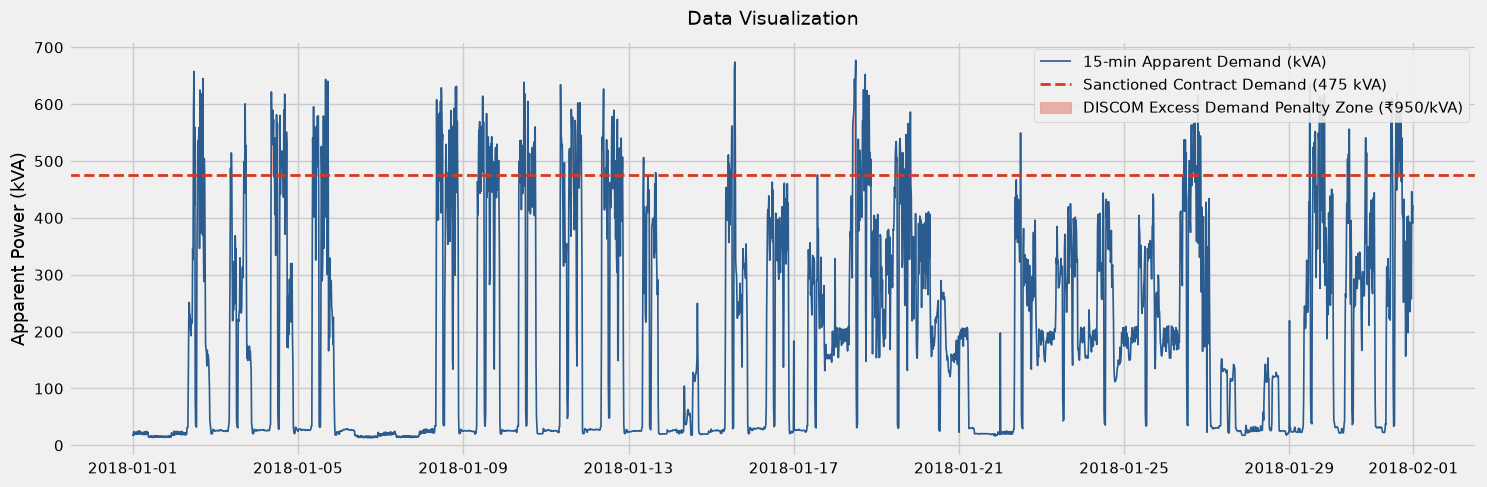

In [6]:
fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(df.index, df['Demand_kVA'], color='#2b5c8f', lw=1.2, label='15-min Apparent Demand (kVA)')
ax.axhline(CONTRACT_DEMAND_KVA, color='#d9381e', linestyle='--', lw=2, label=f'Sanctioned Contract Demand ({CONTRACT_DEMAND_KVA:.0f} kVA)')
ax.fill_between(df.index, CONTRACT_DEMAND_KVA, df['Demand_kVA'], where=(df['Demand_kVA'] > CONTRACT_DEMAND_KVA),
                 color='#d9381e', alpha=0.35, label='DISCOM Excess Demand Penalty Zone (\u20b9950/kVA)')
ax.set_title('Data Visualization', fontsize=14, pad=12)
ax.set_ylabel('Apparent Power (kVA)')
ax.legend(loc='upper right', framealpha=0.9)
plt.tight_layout()
plt.show()

### Feature Engineering

In [7]:
def build_cold_start_features(data, horizon=4):
    d = data.copy()
    
    d['target'] = d['Usage_kWh'].shift(-horizon)
    
    # 1. HISTORICAL USAGE LAGS
    d['usage_now']      = d['Usage_kWh']             # Usage right now at time t
    d['usage_lag_15m']  = d['Usage_kWh'].shift(1)    # 15 mins ago
    d['usage_lag_30m']  = d['Usage_kWh'].shift(2)    # 30 mins ago
    d['usage_lag_1h']   = d['Usage_kWh'].shift(4)    # 1 hour ago
    d['usage_lag_2h']   = d['Usage_kWh'].shift(8)    # 2 hours ago
    d['usage_lag_24h']  = d['Usage_kWh'].shift(96)   # 24 hours ago (yesterday same time)
    
    # 2. ELECTRICAL TELEMETRY
    d['reactive_power_now']    = d['Lagging_Current_Reactive.Power_kVarh']
    d['reactive_power_lag_1h'] = d['Lagging_Current_Reactive.Power_kVarh'].shift(4)
    d['power_factor_now']      = d['Lagging_Current_Power_Factor']
    
    # 3. ROLLING INDUSTRIAL STATISTICS
    d['rolling_max_1h']  = d['Usage_kWh'].rolling(4).max()
    d['rolling_mean_1h'] = d['Usage_kWh'].rolling(4).mean()
    d['rolling_max_4h']  = d['Usage_kWh'].rolling(16).max()
    d['rolling_mean_4h'] = d['Usage_kWh'].rolling(16).mean()
    d['rolling_max_24h'] = d['Usage_kWh'].rolling(96).max()
    
    d['ramp_rate_15m'] = d['Usage_kWh'] - d['Usage_kWh'].shift(1)
    d['ramp_rate_1h']  = d['Usage_kWh'] - d['Usage_kWh'].shift(4)
    
    # 4. CALENDAR & CYCLIC ENCODING
    d['hour']       = d.index.hour
    d['dayofweek']  = d.index.dayofweek
    d['is_weekend'] = (d.index.dayofweek >= 5).astype(int)
    
    # Sine/Cosine encoding preserves circularity
    d['hour_sin'] = np.sin(2 * np.pi * d.index.hour / 24)
    d['hour_cos'] = np.cos(2 * np.pi * d.index.hour / 24)
    
    # Map load types to numerical codes
    load_type_map = {'Light_Load': 0, 'Medium_Load': 1, 'Maximum_Load': 2}
    d['load_type_code'] = d['Load_Type'].map(load_type_map)
    
    # Drop NaNs from the 24h burn-in lag and the future target shift
    d_clean = d.dropna().copy()
    return d_clean

df_feat = build_cold_start_features(df, horizon=FORECAST_HORIZON_STEPS)
print(f"Usable samples after feature engineering: {len(df_feat):,} intervals ({len(df_feat)/96:.1f} days)")

Usable samples after feature engineering: 2,876 intervals (30.0 days)


### Splitting Data

**FIX:** Moved validation start to Jan 19 so the validation window includes
weekday intervals with demand peaks. The old 80/20 split placed validation
in a low-demand weekend window that had only **2 peak intervals** — early
stopping had virtually no signal to optimize for peak prediction.

In [8]:
FEATURE_COLS = [
    'usage_now', 'usage_lag_15m', 'usage_lag_30m', 'usage_lag_1h', 'usage_lag_2h', 'usage_lag_24h',
    'reactive_power_now', 'reactive_power_lag_1h', 'power_factor_now',
    'rolling_max_1h', 'rolling_mean_1h', 'rolling_max_4h', 'rolling_mean_4h', 'rolling_max_24h',
    'ramp_rate_15m', 'ramp_rate_1h',
    'hour', 'dayofweek', 'is_weekend', 'hour_sin', 'hour_cos', 'load_type_code'
]

SPLIT_DATE = pd.Timestamp('2018-01-25 00:00:00')
PURGE_DELTA = pd.Timedelta(minutes=15 * FORECAST_HORIZON_STEPS)

pre_test_df = df_feat.loc[df_feat.index < SPLIT_DATE]
test_df     = df_feat.loc[df_feat.index >= SPLIT_DATE]

# FIX: Use Jan 19 as validation start instead of the old 80% mark.
# This ensures the validation set contains weekday peak intervals.
VALIDATION_START = pd.Timestamp('2018-01-19 00:00:00')
train_end = VALIDATION_START - PURGE_DELTA

train_df = pre_test_df.loc[pre_test_df.index < train_end]
valid_df = pre_test_df.loc[pre_test_df.index >= VALIDATION_START]

X_train, y_train = train_df[FEATURE_COLS], train_df['target']
X_valid, y_valid = valid_df[FEATURE_COLS], valid_df['target']
X_test,  y_test  = test_df[FEATURE_COLS],  test_df['target']

train_peaks = (y_train >= DEMAND_CAP).sum()
valid_peaks = (y_valid >= DEMAND_CAP).sum()
test_peaks  = (y_test >= DEMAND_CAP).sum()

print(f"Training Set   : {len(X_train):,} intervals ({len(X_train)/96:.1f} days) | Peak Spikes (\u2265{DEMAND_CAP:.0f} kWh): {train_peaks}")
print(f"Validation Set : {len(X_valid):,} intervals ({len(X_valid)/96:.1f} days) | Peak Spikes (\u2265{DEMAND_CAP:.0f} kWh): {valid_peaks}")
print(f"Test Set       : {len(X_test):,} intervals ({len(X_test)/96:.1f} days) | Peak Spikes (\u2265{DEMAND_CAP:.0f} kWh): {test_peaks}")

Training Set   : 1,628 intervals (17.0 days) | Peak Spikes (≥100 kWh): 287
Validation Set : 576 intervals (6.0 days) | Peak Spikes (≥100 kWh): 29
Test Set       : 668 intervals (7.0 days) | Peak Spikes (≥100 kWh): 86


### Training the Model

In [9]:
peak_cracker = xgb.XGBRegressor(
    objective='reg:quantileerror',
    quantile_alpha=QUANTILE_ALPHA,
    n_estimators=300,
    learning_rate=0.03,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    early_stopping_rounds=30,
    random_state=42,
    n_jobs=-1,
    device='cuda'
)

# Fit using only the training period; the later test period remains untouched.
peak_cracker.fit(
    X_train, y_train,
    eval_set=[(X_valid, y_valid)],
    verbose=False
)

preds_peak_cracker = peak_cracker.predict(X_test)
rmse_peak_cracker = np.sqrt(mean_squared_error(y_test, preds_peak_cracker))

actual_peaks = (y_test >= DEMAND_CAP)
total_actual_peaks = int(actual_peaks.sum())

peak_cracker_alerted = (preds_peak_cracker >= DEMAND_CAP)
peak_cracker_caught  = int((actual_peaks & peak_cracker_alerted).sum())
peak_cracker_missed  = total_actual_peaks - peak_cracker_caught
peak_cracker_recall  = (peak_cracker_caught / total_actual_peaks) * 100

print(f"Total Demand Breach Spikes (\u2265{DEMAND_CAP:.0f} kWh): {total_actual_peaks}")
print(f"Spikes Caught (True Positives): {peak_cracker_caught}")
print(f"Missed Spikes: {peak_cracker_missed}")
print(f"Peak Detection Recall (%): {peak_cracker_recall:.1f}%")
print(f"Overall Test RMSE (kWh): {rmse_peak_cracker:.2f}")

Total Demand Breach Spikes (≥100 kWh): 86
Spikes Caught (True Positives): 80
Missed Spikes: 6
Peak Detection Recall (%): 93.0%
Overall Test RMSE (kWh): 46.08


### Visualization and Analysis

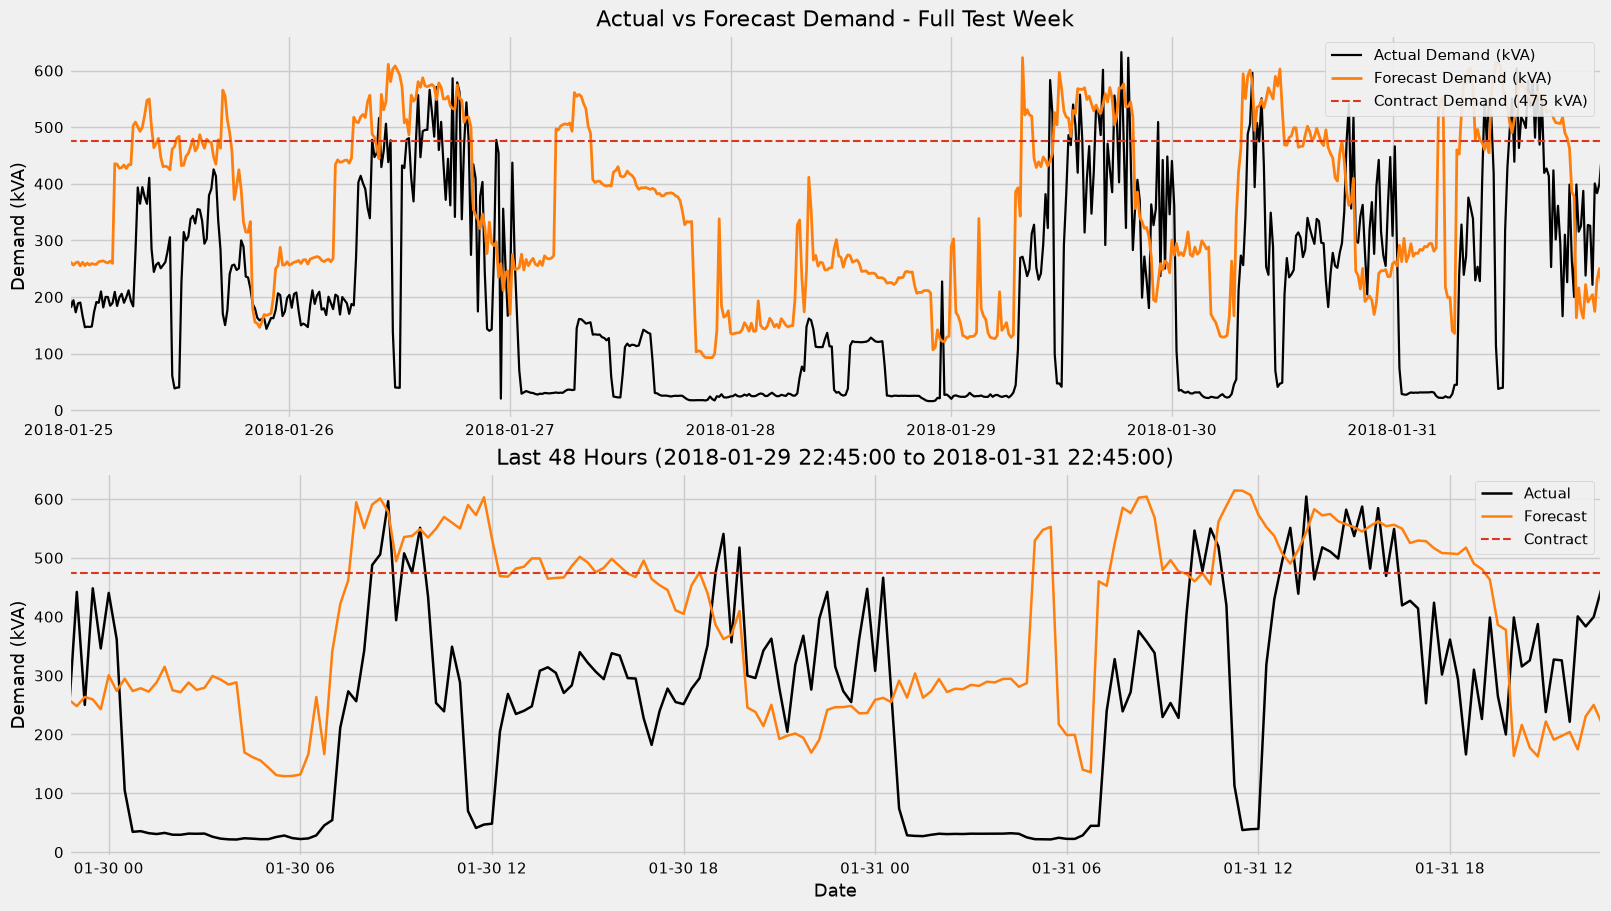

In [10]:
# Simplified actual-vs-forecast demand plot
pf_test = test_df['Lagging_Current_Power_Factor'].clip(lower=50.0) / 100.0
actual_kva_test = (y_test * 4) / pf_test
peak_cracker_kva_test = (preds_peak_cracker * 4) / pf_test

fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=False, constrained_layout=True)

# Full test window
axes[0].plot(test_df.index, actual_kva_test, color='black', lw=1.6, label='Actual Demand (kVA)')
axes[0].plot(test_df.index, peak_cracker_kva_test, color='#ff7f0e', lw=2.0, label='Forecast Demand (kVA)')
axes[0].axhline(CONTRACT_DEMAND_KVA, color='#d9381e', linestyle='--', lw=1.5, label=f'Contract Demand ({CONTRACT_DEMAND_KVA:.0f} kVA)')
axes[0].set_title('Actual vs Forecast Demand - Full Test Week')
axes[0].set_ylabel('Demand (kVA)')
axes[0].legend(loc='upper right', framealpha=0.9)
axes[0].set_xlim(test_df.index.min(), test_df.index.max())
axes[0].margins(x=0)

# Last 48 hours
zoom_start = test_df.index.max() - pd.Timedelta(hours=48)
zoom_mask = (test_df.index >= zoom_start) & (test_df.index <= test_df.index.max())

axes[1].plot(test_df.index[zoom_mask], actual_kva_test[zoom_mask], color='black', lw=1.8, label='Actual')
axes[1].plot(test_df.index[zoom_mask], peak_cracker_kva_test[zoom_mask], color='#ff7f0e', lw=1.8, label='Forecast')
axes[1].axhline(CONTRACT_DEMAND_KVA, color='#d9381e', linestyle='--', lw=1.5, label='Contract')
axes[1].set_title(f'Last 48 Hours ({zoom_start} to {test_df.index.max()})')
axes[1].set_ylabel('Demand (kVA)')
axes[1].set_xlabel('Date')
axes[1].legend(loc='upper right', framealpha=0.9)
axes[1].set_xlim(zoom_start, test_df.index.max())
axes[1].margins(x=0)

plt.show()

### BESS Simulation — Peak Shaving

**What changed from MK1 (and why):**

1. **kVA-aware discharge trigger:** MK1 discharged whenever `forecast_kWh ≥ 100`.
   But billing is based on `kVA = kWh × 4 ÷ PF`, so a moderate-kWh interval with bad
   power factor can produce a higher kVA spike than a high-kWh interval with good PF.
   **Fix:** convert the forecast to *estimated kVA* using the current power factor and
   trigger discharge only when `estimated_kVA ≥ 500`.

2. **Conservative discharge target:** Instead of trying to bring every spike all the way
   down to contract demand (475 kVA) — which drains the battery fast — we target 500 kVA.
   Smaller discharges preserve SoC for later, potentially bigger spikes.

3. **Safe charging:** MK1 charged only when `forecast < 45 kWh` (too restrictive) and
   didn't check whether charging itself would push grid import above contract demand.
   **Fix:** charge whenever there’s kVA headroom below 475 kVA, capped so charging
   load itself never creates a new demand spike.

In [11]:
def simulate_bess_shaving(actual_usage, forecast_usage, pf_current,
                          contract_kva=475.0,
                          kva_discharge_trigger=500.0,
                          kva_discharge_target=500.0,
                          bess_cap=500.0,
                          max_discharge=45.0,
                          max_charge=25.0,
                          min_soc_reserve_frac=0.10):
    """
    kVA-aware BESS simulation for demand-charge peak shaving.

    Key improvements over MK1:
    ─────────────────────────────────────────────────────────────────
    • Discharge decision uses ESTIMATED kVA (= forecast_kWh × 4 / PF),
      not raw kWh, so it tracks the actual billing metric.
    • Discharge target is adjustable (default 500 kVA) to avoid draining
      the battery trying to reach 475 kVA every single time.
    • Charges only when there’s kVA headroom below contract demand, so
      charging itself never creates a new demand spike.
    • Maintains a minimum SoC reserve so the battery is never fully empty
      when a surprise peak arrives.
    """
    soc = bess_cap * 0.9           # Start at 90% SoC
    reserve = bess_cap * min_soc_reserve_frac
    net_grid_load = []
    shaved_power = []
    soc_trace = []

    for actual, forecast, pf in zip(actual_usage, forecast_usage, pf_current):
        estimated_kva = (forecast * 4) / pf

        if estimated_kva >= kva_discharge_trigger and soc > reserve:
            # ── DISCHARGE ──────────────────────────────────────────────────
            # How many kWh would bring the predicted kVA down to the target?
            target_kwh = kva_discharge_target * pf / 4
            excess_kwh = max(0.0, forecast - target_kwh)
            planned_discharge = min(excess_kwh, max_discharge, soc - reserve)
            soc -= planned_discharge
            net_grid = max(0.0, actual - planned_discharge)
            shaved_power.append(min(planned_discharge, actual))
        else:
            shaved_power.append(0.0)
            # ── SAFE CHARGING ───────────────────────────────────────────────
            # Only charge when it won't push grid import above contract demand.
            actual_kva = (actual * 4) / pf
            headroom_kva = contract_kva - actual_kva
            headroom_kwh = max(0.0, headroom_kva * pf / 4)
            if headroom_kwh > 2.0 and soc < bess_cap:
                charge = min(max_charge, bess_cap - soc, headroom_kwh)
                soc += charge * 0.95      # 95% round-trip charging efficiency
                net_grid = actual + charge
            else:
                net_grid = actual
        net_grid_load.append(net_grid)
        soc_trace.append(soc)

    return np.array(net_grid_load), np.array(shaved_power), np.array(soc_trace)


# ── Run the simulation ─────────────────────────────────────────────────────
pf_test_arr = test_df['power_factor_now'].clip(lower=50.0).to_numpy() / 100.0

net_grid, shaved_power, soc_trace = simulate_bess_shaving(
    y_test.to_numpy(),
    preds_peak_cracker,
    pf_test_arr,
    contract_kva=CONTRACT_DEMAND_KVA,
    kva_discharge_trigger=500.0,   # Only discharge when est. kVA ≥ 500
    kva_discharge_target=500.0,    # Target: bring peaks down to 500 kVA
    min_soc_reserve_frac=0.10      # Keep 10% SoC in reserve
)

# ── Billing calculation ────────────────────────────────────────────────────
raw_kva     = (y_test.to_numpy() * 4) / pf_test_arr
managed_kva = (net_grid * 4)          / pf_test_arr

def calc_demand_charge(
    kva_series,
    contract_demand=475.0,
    minimum_billing_ratio=0.80,
    normal_rate=475.0,
    penalty_rate=950.0,
 ):
    recorded_demand = float(np.max(kva_series))
    billed_demand = max(recorded_demand, contract_demand * minimum_billing_ratio)
    base_charge = min(billed_demand, contract_demand) * normal_rate
    excess_demand = max(0.0, recorded_demand - contract_demand)
    penalty = excess_demand * penalty_rate
    return recorded_demand, excess_demand, base_charge + penalty

raw_rmd, raw_excess, raw_charge = calc_demand_charge(raw_kva)
managed_rmd, managed_excess, managed_charge = calc_demand_charge(managed_kva)
savings = raw_charge - managed_charge

print('Peak Cracker MK2 \u2014 BESS Impact')
print('=' * 40)
print(f'Unmanaged RMD       : {raw_rmd:,.1f} kVA')
print(f'Managed RMD         : {managed_rmd:,.1f} kVA')
print(f'RMD reduction       : {raw_rmd - managed_rmd:,.1f} kVA')
print(f'Unmanaged charge    : \u20b9 {raw_charge:,.2f}')
print(f'Managed charge      : \u20b9 {managed_charge:,.2f}')
print(f'Estimated savings   : \u20b9 {savings:,.2f}')
print(f'Energy shaved       : {sum(shaved_power):,.1f} kWh')

Peak Cracker MK2 — BESS Impact
Unmanaged RMD       : 632.6 kVA
Managed RMD         : 586.3 kVA
RMD reduction       : 46.4 kVA
Unmanaged charge    : ₹ 375,385.99
Managed charge      : ₹ 331,317.49
Estimated savings   : ₹ 44,068.50
Energy shaved       : 1,611.5 kWh


### Battery State-of-Charge and Managed Demand

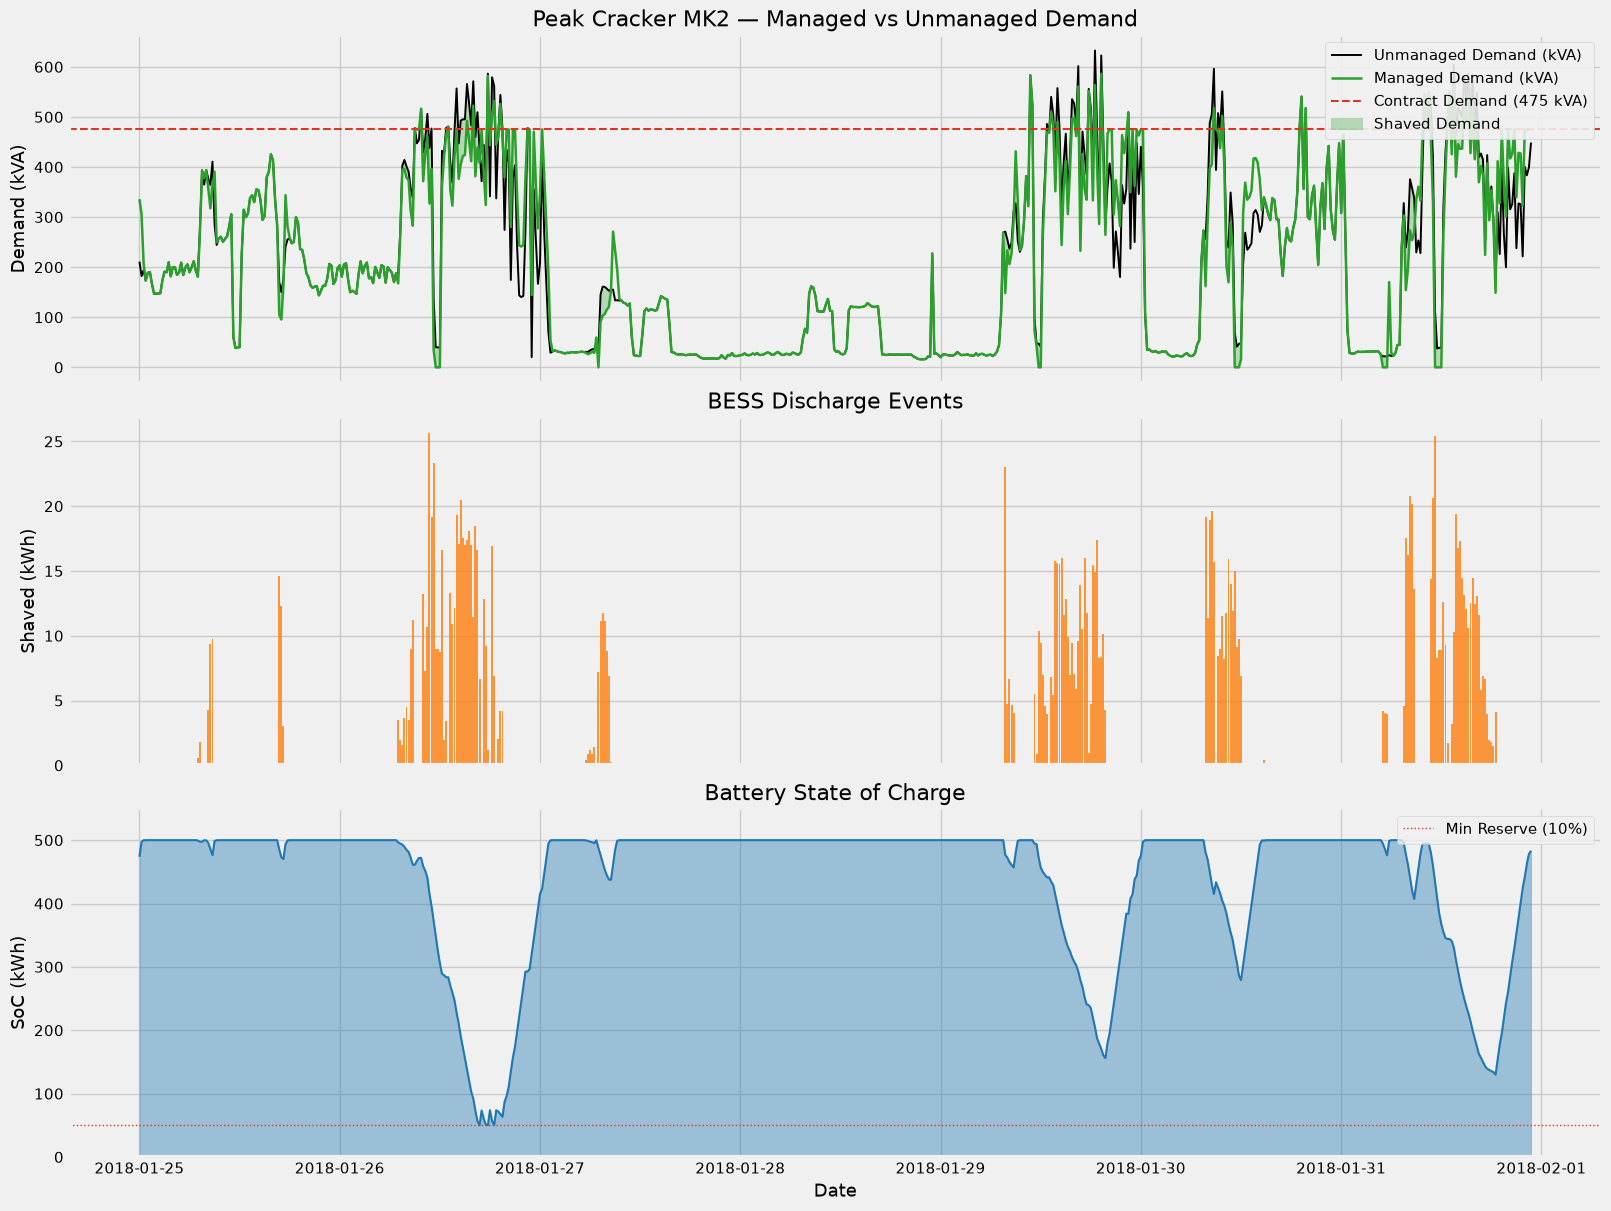

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True, constrained_layout=True)

# Panel 1: Actual vs Managed kVA
axes[0].plot(test_df.index, raw_kva, color='black', lw=1.4, label='Unmanaged Demand (kVA)')
axes[0].plot(test_df.index, managed_kva, color='#2ca02c', lw=1.8, label='Managed Demand (kVA)')
axes[0].axhline(CONTRACT_DEMAND_KVA, color='#d9381e', ls='--', lw=1.5, label=f'Contract Demand ({CONTRACT_DEMAND_KVA:.0f} kVA)')
axes[0].fill_between(test_df.index, raw_kva, managed_kva, where=(raw_kva > managed_kva),
                      color='#2ca02c', alpha=0.3, label='Shaved Demand')
axes[0].set_ylabel('Demand (kVA)')
axes[0].set_title('Peak Cracker MK2 \u2014 Managed vs Unmanaged Demand')
axes[0].legend(loc='upper right', framealpha=0.9)

# Panel 2: Shaved power
axes[1].bar(test_df.index, shaved_power, width=pd.Timedelta(minutes=14), color='#ff7f0e', alpha=0.8)
axes[1].set_ylabel('Shaved (kWh)')
axes[1].set_title('BESS Discharge Events')

# Panel 3: SoC
axes[2].fill_between(test_df.index, 0, soc_trace, color='#1f77b4', alpha=0.4)
axes[2].plot(test_df.index, soc_trace, color='#1f77b4', lw=1.5)
axes[2].axhline(500 * 0.10, color='#d9381e', ls=':', lw=1, label='Min Reserve (10%)')
axes[2].set_ylabel('SoC (kWh)')
axes[2].set_xlabel('Date')
axes[2].set_title('Battery State of Charge')
axes[2].set_ylim(0, 550)
axes[2].legend(loc='upper right')

plt.show()